# 02 — ACM et rapprochement de modalités

Les règles de recodification et d’exclusion sont identiques à celles du notebook fourni. La condition de contribution sur les cinq premiers axes est conservée.

In [1]:
from pathlib import Path
import sys

RACINE = Path.cwd().resolve()
if RACINE.name == 'notebooks':
    RACINE = RACINE.parent
sys.path.insert(0, str(RACINE))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import yaml
from src.preparation import preparer_donnees, charger_regroupements, decrire_distributions
from src.acm import (
    executer_iteration_1, executer_iteration_2, executer_iteration_3,
    selectionner_paires_proches, charger_regroupements_acm_finaux,
)
from src.proximite_modalites import comparer_modalites

In [2]:
donnees_brutes = pd.read_csv(RACINE / 'data/brutes/td_clustering_karafun.csv')
regroupements = charger_regroupements(RACINE / 'config/regroupements.yaml')
donnees_preparees, donnees_nettoyees = preparer_donnees(donnees_brutes, regroupements)
for variable, tableau in decrire_distributions(donnees_preparees).items():
    print(f'\n=== {variable} ===')
    display(tableau)



=== anciennete_client_rec ===


,Fréquence,Pourcentage (%)
anciennete_client_rec,,
02_6_a_12_mois,98460,28.87
01_Moins_de_6_mois,67839,19.89
04_2_a_4_ans,63540,18.63
03_1_a_2_ans,62930,18.45
05_Plus_de_4_ans,48322,14.17



=== anciennete_abonnement_rec ===


,Fréquence,Pourcentage (%)
anciennete_abonnement_rec,,
03_6_a_12_mois,131873,38.66
01_Moins_de_3_mois,69795,20.46
02_3_a_5_mois,52697,15.45
04_1_a_2_ans,45378,13.30
05_Plus_de_2_ans,41348,12.12



=== methode_paiement_rec ===


,Fréquence,Pourcentage (%)
methode_paiement_rec,,
web_et_direct,172829,50.67
telephone,164814,48.32
Amazon,2846,0.83
Credit,602,0.18


... (4 outputs left out)


=== avg_songs_sessions_rec ===


,Fréquence,Pourcentage (%)
avg_songs_sessions_rec,,
01_Faible_1_a_5,97035,28.45
02_Moyen_5_a_10,80920,23.72
03_Eleve_10_a_20,76782,22.51
04_Tres_eleve_20_et_plus,45639,13.38
00_Inactif,40715,11.94



=== zone_geo_rec ===


,Fréquence,Pourcentage (%)
zone_geo_rec,,
02_Europe,155980,45.73
01_US,140841,41.29
03_CA,23999,7.04
04_Reste_du_Monde,20271,5.94


## Itération 1 — Toutes les variables actives

Itération 1 : 68218 individus, 11 variables
Nombre de modalités actives (K) : 47
Nombre d'axes factoriels calculés : 36

=== Inertie expliquée par les axes factoriels (p = 11 variables, 1/p = 0.091) ===
   Axe  Valeur Propre λ > 1/p  Inertie Brute (%)  Inertie Brute Cumulée (%)  Inertie Benzécri (%)  Inertie Benzécri Cumulée (%)
 Axe 1           0.30     oui               9.29                       9.29                 51.67                         51.67
 Axe 2           0.23     oui               7.16                      16.45                 23.42                         75.09
 Axe 3           0.19     oui               5.85                      22.30                 11.54                         86.63
 Axe 4           0.16     oui               4.88                      27.18                  5.37                         92.01
 Axe 5           0.15     oui               4.54                      31.71                  3.78                         95.79
 Axe 6           0.13     oui

,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 1,Contrib Axe 1 (%)
type_client__churn,type_client,churn,34314,50.3,-0.506,3.86
type_client__nouveau,type_client,nouveau,10980,16.1,-0.522,1.31
type_client__reactivated,type_client,reactivated,9932,14.6,0.085,0.03
type_client__retained,type_client,retained,12992,19.0,1.714,16.73
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.756,4.67
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.356,0.44
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.104,0.04
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,0.666,1.25
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.662,4.76
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,-1.193,1.53



--- Axe 2 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 2,Contrib Axe 2 (%)
type_client__churn,type_client,churn,34314,50.3,-0.635,7.87
type_client__nouveau,type_client,nouveau,10980,16.1,1.468,13.46
type_client__reactivated,type_client,reactivated,9932,14.6,0.402,0.91
type_client__retained,type_client,retained,12992,19.0,0.129,0.12
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.783,6.50
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.413,0.76
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.190,0.17
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.254,0.24
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.619,5.40
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,2.332,7.56



--- Axe 3 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 3,Contrib Axe 3 (%)
type_client__churn,type_client,churn,34314,50.3,-0.035,0.03
type_client__nouveau,type_client,nouveau,10980,16.1,0.665,3.38
type_client__reactivated,type_client,reactivated,9932,14.6,-0.536,1.98
type_client__retained,type_client,retained,12992,19.0,-0.061,0.03
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.339,1.49
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.031,0.01
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,0.105,0.06
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.216,0.21
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.094,0.15
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,1.953,6.48


... (4 outputs left out)


=== Diagnostic par variable ===


,Nb modalités,Nb modalités > seuil,Contrib max (%),Max Axe 1 (%),Max Axe 2 (%),Max Axe 3 (%),Max Axe 4 (%),Max Axe 5 (%),Statut
Variable,,,,,,,,,
zone_geo_rec,4,0,0.56,0.56,0.09,0.21,0.39,0.22,À RETIRER ?
utilise_remote,2,1,2.58,0.21,1.14,2.58,0.51,1.92,OK
methode_paiement_rec,4,2,4.37,0.56,0.01,0.22,1.01,4.37,OK
ratio_fidelite_tr,6,6,7.56,4.76,7.56,6.48,6.66,5.90,OK
contactable,2,2,7.92,0.71,1.03,0.23,1.80,7.92,OK
valeur_12M_rec,5,5,9.36,7.57,0.88,0.73,9.36,4.14,OK
anciennete_abonnement_rec,5,5,10.65,10.65,8.50,4.88,7.98,5.08,OK
anciennete_client_rec,5,5,10.85,3.49,10.85,8.53,9.98,7.11,OK
type_client,4,4,16.73,16.73,13.46,3.38,7.81,5.99,OK


Variables à examiner pour la prochaine itération : ['zone_geo_rec']
variables_a_retirer à copier = ['zone_geo_rec']

=== Proximité des modalités sur les 5 premiers axes ===
Quantile (10%) : 0.5061
Moyenne - écart-type : 0.8723
9 paire(s) candidate(s) sur 85


,Variable,Modalité A,Modalité B,Effectif A,Effectif B,Distance,Dans les plus proches (%),Sous moyenne - écart-type,Candidate ?
0,zone_geo_rec,02_Europe,04_Reste_du_Monde,31107,4128,0.217,True,True,True
1,avg_songs_sessions_rec,03_Eleve_10_a_20,04_Tres_eleve_20_et_plus,15337,8962,0.275,True,True,True
2,zone_geo_rec,02_Europe,03_CA,31107,4791,0.358,True,True,True
3,avg_sessions_actifs_rec,02_Moyen_2_a_4,03_Eleve_4_a_8,15142,9497,0.398,True,True,True
4,avg_songs_sessions_rec,02_Moyen_5_a_10,03_Eleve_10_a_20,16299,15337,0.403,True,True,True
5,zone_geo_rec,01_US,04_Reste_du_Monde,28192,4128,0.430,True,True,True
6,avg_songs_sessions_rec,01_Faible_1_a_5,02_Moyen_5_a_10,19480,16299,0.439,True,True,True
7,ratio_fidelite_tr,02_30a50,03_50a70,7877,8087,0.445,True,True,True
8,zone_geo_rec,03_CA,04_Reste_du_Monde,4791,4128,0.506,True,True,True
9,zone_geo_rec,01_US,02_Europe,28192,31107,0.507,False,True,False


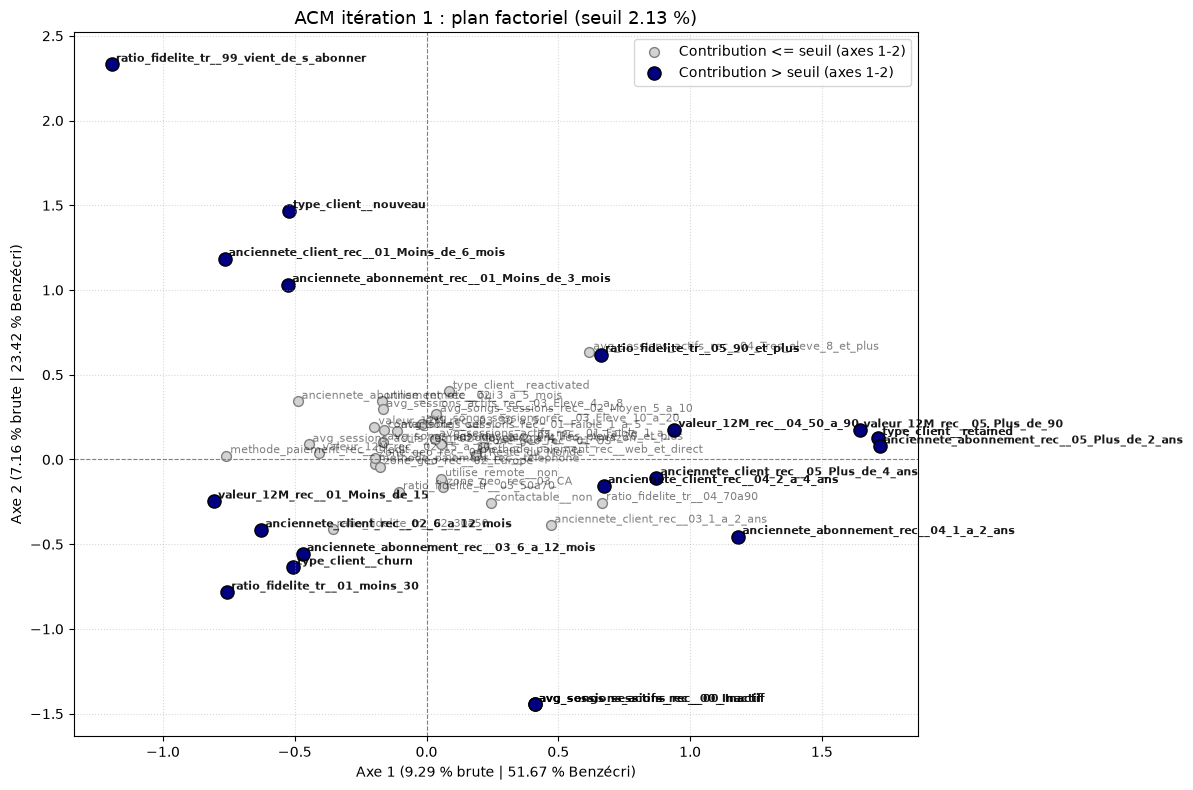

In [3]:
resultats_iteration_1 = executer_iteration_1(donnees_nettoyees, variables_a_retirer=[])


## Itération 2 — Retrait de `zone_geo_rec`

Itération 2 : 68218 individus, 10 variables
Nombre de modalités actives (K) : 43
Nombre d'axes factoriels calculés : 33

=== Inertie expliquée par les axes factoriels (p = 10 variables, 1/p = 0.100) ===
   Axe  Valeur Propre λ > 1/p  Inertie Brute (%)  Inertie Brute Cumulée (%)  Inertie Benzécri (%)  Inertie Benzécri Cumulée (%)
 Axe 1           0.33     oui              10.06                      10.06                 51.56                         51.56
 Axe 2           0.26     oui               7.80                      17.86                 23.78                         75.34
 Axe 3           0.21     oui               6.37                      24.23                 11.65                         86.99
 Axe 4           0.18     oui               5.30                      29.53                  5.40                         92.39
 Axe 5           0.16     oui               4.94                      34.48                  3.83                         96.22
 Axe 6           0.14     oui

,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 1,Contrib Axe 1 (%)
type_client__churn,type_client,churn,34314,50.3,-0.501,3.81
type_client__nouveau,type_client,nouveau,10980,16.1,-0.541,1.42
type_client__reactivated,type_client,reactivated,9932,14.6,0.081,0.03
type_client__retained,type_client,retained,12992,19.0,1.719,16.97
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.745,4.57
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.358,0.45
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.111,0.04
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,0.667,1.26
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.658,4.74
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,-1.215,1.59



--- Axe 2 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 2,Contrib Axe 2 (%)
type_client__churn,type_client,churn,34314,50.3,-0.639,7.97
type_client__nouveau,type_client,nouveau,10980,16.1,1.457,13.28
type_client__reactivated,type_client,reactivated,9932,14.6,0.404,0.92
type_client__retained,type_client,retained,12992,19.0,0.146,0.16
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.784,6.52
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.417,0.78
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.196,0.18
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.250,0.23
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.624,5.48
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,2.314,7.45



--- Axe 3 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 3,Contrib Axe 3 (%)
type_client__churn,type_client,churn,34314,50.3,-0.043,0.04
type_client__nouveau,type_client,nouveau,10980,16.1,0.671,3.45
type_client__reactivated,type_client,reactivated,9932,14.6,-0.541,2.03
type_client__retained,type_client,retained,12992,19.0,-0.041,0.01
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.342,1.52
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.045,0.01
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,0.089,0.04
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.222,0.22
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.104,0.19
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,1.990,6.75


... (4 outputs left out)


=== Diagnostic par variable ===


,Nb modalités,Nb modalités > seuil,Contrib max (%),Max Axe 1 (%),Max Axe 2 (%),Max Axe 3 (%),Max Axe 4 (%),Max Axe 5 (%),Statut
Variable,,,,,,,,,
utilise_remote,2,1,2.56,0.22,1.16,2.56,0.53,1.87,OK
methode_paiement_rec,4,2,4.34,0.61,0.02,0.17,0.85,4.34,OK
ratio_fidelite_tr,6,6,7.45,4.74,7.45,6.75,6.73,5.96,OK
contactable,2,2,8.06,0.76,0.98,0.19,1.62,8.06,OK
valeur_12M_rec,5,5,9.07,7.27,0.91,0.76,9.07,4.29,OK
anciennete_client_rec,5,5,10.64,3.65,10.64,8.71,10.48,7.31,OK
anciennete_abonnement_rec,5,5,10.79,10.79,8.40,5.10,7.99,5.00,OK
type_client,4,4,16.97,16.97,13.28,3.45,8.07,5.85,OK
avg_sessions_actifs_rec,5,2,23.46,1.31,9.87,23.46,2.64,0.70,OK


Variables à examiner pour la prochaine itération : aucune
variables_a_retirer à copier = ['zone_geo_rec']

=== Proximité des modalités sur les 5 premiers axes ===
Quantile (10%) : 0.7616
Moyenne - écart-type : 1.0310
8 paire(s) candidate(s) sur 79


,Variable,Modalité A,Modalité B,Effectif A,Effectif B,Distance,Dans les plus proches (%),Sous moyenne - écart-type,Candidate ?
0,avg_songs_sessions_rec,03_Eleve_10_a_20,04_Tres_eleve_20_et_plus,15337,8962,0.279,True,True,True
1,avg_sessions_actifs_rec,02_Moyen_2_a_4,03_Eleve_4_a_8,15142,9497,0.401,True,True,True
2,avg_songs_sessions_rec,02_Moyen_5_a_10,03_Eleve_10_a_20,16299,15337,0.401,True,True,True
3,avg_songs_sessions_rec,01_Faible_1_a_5,02_Moyen_5_a_10,19480,16299,0.434,True,True,True
4,ratio_fidelite_tr,02_30a50,03_50a70,7877,8087,0.443,True,True,True
5,methode_paiement_rec,Amazon,telephone,543,32926,0.644,True,True,True
6,anciennete_client_rec,04_2_a_4_ans,05_Plus_de_4_ans,12626,9586,0.653,True,True,True
7,avg_songs_sessions_rec,02_Moyen_5_a_10,04_Tres_eleve_20_et_plus,16299,8962,0.656,True,True,True
8,avg_songs_sessions_rec,01_Faible_1_a_5,03_Eleve_10_a_20,19480,15337,0.788,False,True,False
9,avg_sessions_actifs_rec,01_Faible_1_a_2,03_Eleve_4_a_8,28866,9497,0.800,False,True,False


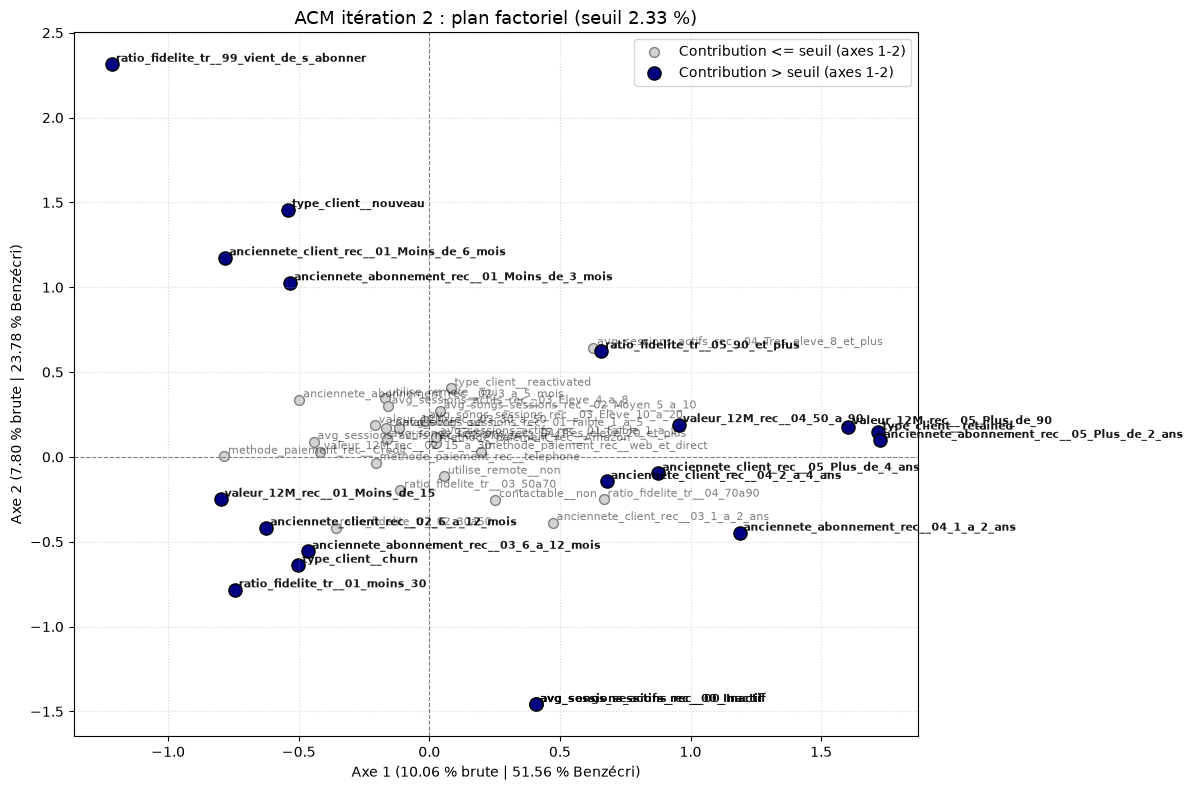

In [4]:
resultats_iteration_2 = executer_iteration_2(donnees_nettoyees, variables_a_retirer=['zone_geo_rec'])


## Sélection des paires candidates après l’itération 2

Les distances euclidiennes sont calculées entre modalités **d’une même variable** sur les cinq premiers axes. On retient les paires qui satisfont **simultanément** :

- une distance parmi les 20 % les plus faibles ;
- une distance inférieure ou égale à la moyenne moins un écart-type.

Ces seuils sont des règles exploratoires calculées sur les données, **pas une preuve de proximité**. Si aucune paire ne satisfait les deux critères, aucune fusion n’est imposée. Les regroupements seront décidés manuellement.


In [5]:
# Sélection sans seuil fixe de 0,10
PROPORTION_SELECTION = 0.10

paires_modalites, statistiques_proximite = selectionner_paires_proches(
    resultats_iteration_2["proximites"][[
        "Variable", "Modalité A", "Modalité B", "Effectif A", "Effectif B", "Distance"
    ]],
    proportion=PROPORTION_SELECTION,
)

print(f"Nombre de paires comparées : {statistiques_proximite['nombre_paires']}")
print(f"Seuil du quantile : {statistiques_proximite['seuil_quantile']:.4f}")
print(f"Seuil moyenne - écart-type : {statistiques_proximite['seuil_distance']:.4f}")
print(f"Nombre de paires candidates : {statistiques_proximite['nombre_candidates']}")
display(paires_modalites)

dossier_resultats = RACINE / "resultats"
dossier_resultats.mkdir(parents=True, exist_ok=True)
paires_modalites.to_csv(dossier_resultats / "paires_modalites_acm_2.csv", index=False)


Nombre de paires comparées : 79
Seuil du quantile : 0.7616
Seuil moyenne - écart-type : 1.0310
Nombre de paires candidates : 8


,Variable,Modalité A,Modalité B,Effectif A,Effectif B,Distance,Dans les plus proches (%),Sous moyenne - écart-type,Candidate ?
0,avg_songs_sessions_rec,03_Eleve_10_a_20,04_Tres_eleve_20_et_plus,15337,8962,0.279044,True,True,True
1,avg_sessions_actifs_rec,02_Moyen_2_a_4,03_Eleve_4_a_8,15142,9497,0.401391,True,True,True
2,avg_songs_sessions_rec,02_Moyen_5_a_10,03_Eleve_10_a_20,16299,15337,0.401413,True,True,True
3,avg_songs_sessions_rec,01_Faible_1_a_5,02_Moyen_5_a_10,19480,16299,0.433849,True,True,True
4,ratio_fidelite_tr,02_30a50,03_50a70,7877,8087,0.442609,True,True,True
...,...,...,...,...,...,...,...,...,...
74,ratio_fidelite_tr,05_90_et_plus,99_vient_de_s_abonner,24746,2444,3.476211,False,False,False
75,ratio_fidelite_tr,01_moins_30,99_vient_de_s_abonner,18647,2444,3.983032,False,False,False
76,ratio_fidelite_tr,03_50a70,99_vient_de_s_abonner,8087,2444,4.113588,False,False,False
77,ratio_fidelite_tr,02_30a50,99_vient_de_s_abonner,7877,2444,4.119124,False,False,False


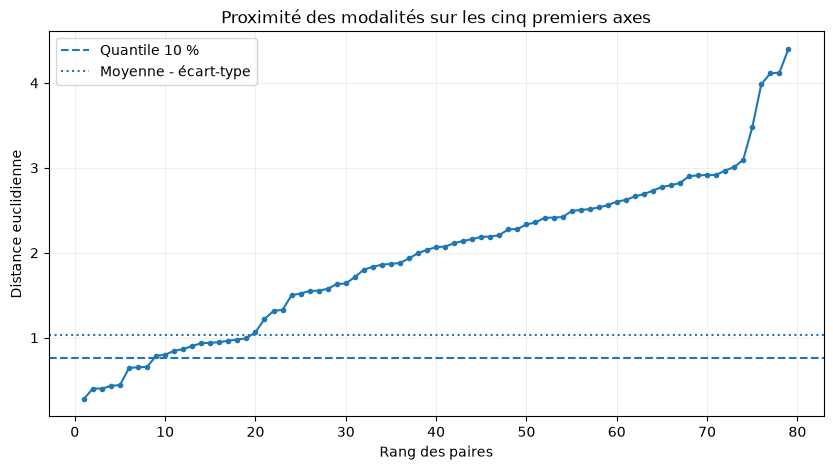

In [6]:
# Visualisation de la distribution des distances et des seuils
fig, axe = plt.subplots(figsize=(10, 5))
axe.plot(np.arange(1, len(paires_modalites) + 1), paires_modalites["Distance"], marker=".")
axe.axhline(statistiques_proximite["seuil_quantile"], linestyle="--", label="Quantile 10 %")
axe.axhline(statistiques_proximite["seuil_distance"], linestyle=":", label="Moyenne - écart-type")
axe.set(xlabel="Rang des paires", ylabel="Distance euclidienne",
        title="Proximité des modalités sur les cinq premiers axes")
axe.grid(alpha=0.2)
axe.legend()
plt.show()


## Itération 3 — Regroupement final retenu

À partir des distances euclidiennes sur les cinq premiers axes de l'ACM 2, la paire « 10–20 » et « 20 et plus » chansons par session a été retenue : c'est la plus proche parmi les candidates. Le regroupement est justifié également par une interprétation métier commune : une consommation élevée.

Les autres paires ont été examinées mais conservées séparées. La fusion définitive figure dans `config/regroupements.yaml`, dans une section dédiée afin de reproduire sans modification les itérations 1 et 2.

**La même population et la même graine sont conservées pour comparer les deux ACM.**

In [7]:
# Chargement de la décision définitive depuis la configuration
regroupements_finaux = charger_regroupements_acm_finaux(
    RACINE / "config/regroupements.yaml"
)

if regroupements_finaux != {
    "avg_songs_sessions_rec": {
        "03_10_et_plus": ["03_Eleve_10_a_20", "04_Tres_eleve_20_et_plus"]
    }
}:
    raise ValueError("La configuration du regroupement final ne correspond pas à la décision validée.")

print("Regroupement final retenu :", regroupements_finaux)

Regroupement final retenu : {'avg_songs_sessions_rec': {'03_10_et_plus': ['03_Eleve_10_a_20', '04_Tres_eleve_20_et_plus']}}


### Calcul de l'ACM final

La troisième itération applique **une seule fusion** sur les données préalablement préparées, sans modifier les données utilisées par les deux premières itérations. Aucune quatrième itération n'est nécessaire à ce stade.

Itération 3 : 68218 individus, 10 variables
Nombre de modalités actives (K) : 42
Nombre d'axes factoriels calculés : 32

=== Inertie expliquée par les axes factoriels (p = 10 variables, 1/p = 0.100) ===
   Axe  Valeur Propre λ > 1/p  Inertie Brute (%)  Inertie Brute Cumulée (%)  Inertie Benzécri (%)  Inertie Benzécri Cumulée (%)
 Axe 1           0.33     oui              10.37                      10.37                 51.61                         51.61
 Axe 2           0.26     oui               8.04                      18.41                 23.81                         75.42
 Axe 3           0.21     oui               6.57                      24.98                 11.67                         87.09
 Axe 4           0.18     oui               5.47                      30.45                  5.41                         92.50
 Axe 5           0.16     oui               5.10                      35.54                  3.82                         96.32
 Axe 6           0.14     oui

,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 1,Contrib Axe 1 (%)
type_client__churn,type_client,churn,34314,50.3,-0.500,3.80
type_client__nouveau,type_client,nouveau,10980,16.1,-0.543,1.43
type_client__reactivated,type_client,reactivated,9932,14.6,0.080,0.03
type_client__retained,type_client,retained,12992,19.0,1.719,16.97
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.743,4.55
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.358,0.45
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.111,0.04
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,0.668,1.26
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.657,4.73
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,-1.217,1.60



--- Axe 2 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 2,Contrib Axe 2 (%)
type_client__churn,type_client,churn,34314,50.3,-0.639,7.98
type_client__nouveau,type_client,nouveau,10980,16.1,1.456,13.26
type_client__reactivated,type_client,reactivated,9932,14.6,0.404,0.92
type_client__retained,type_client,retained,12992,19.0,0.148,0.16
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.784,6.53
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.418,0.78
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,-0.197,0.18
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.249,0.23
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.624,5.50
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,2.312,7.44



--- Axe 3 ---


,Variable,Modalité,Effectif,Fréquence (%),Coord Axe 3,Contrib Axe 3 (%)
type_client__churn,type_client,churn,34314,50.3,-0.043,0.05
type_client__nouveau,type_client,nouveau,10980,16.1,0.672,3.46
type_client__reactivated,type_client,reactivated,9932,14.6,-0.541,2.03
type_client__retained,type_client,retained,12992,19.0,-0.040,0.01
ratio_fidelite_tr__01_moins_30,ratio_fidelite_tr,01_moins_30,18647,27.3,-0.343,1.53
ratio_fidelite_tr__02_30a50,ratio_fidelite_tr,02_30a50,7877,11.5,-0.045,0.01
ratio_fidelite_tr__03_50a70,ratio_fidelite_tr,03_50a70,8087,11.9,0.088,0.04
ratio_fidelite_tr__04_70a90,ratio_fidelite_tr,04_70a90,6417,9.4,-0.222,0.22
ratio_fidelite_tr__05_90_et_plus,ratio_fidelite_tr,05_90_et_plus,24746,36.3,0.105,0.19
ratio_fidelite_tr__99_vient_de_s_abonner,ratio_fidelite_tr,99_vient_de_s_abonner,2444,3.6,1.992,6.77


... (4 outputs left out)


=== Diagnostic par variable ===


,Nb modalités,Nb modalités > seuil,Contrib max (%),Max Axe 1 (%),Max Axe 2 (%),Max Axe 3 (%),Max Axe 4 (%),Max Axe 5 (%),Statut
Variable,,,,,,,,,
utilise_remote,2,1,2.53,0.21,1.17,2.53,0.52,1.76,OK
methode_paiement_rec,4,2,4.23,0.62,0.02,0.16,0.86,4.23,OK
ratio_fidelite_tr,6,6,7.44,4.73,7.44,6.77,6.73,6.05,OK
contactable,2,2,8.02,0.77,0.98,0.19,1.63,8.02,OK
valeur_12M_rec,5,5,9.08,7.28,0.92,0.76,9.08,4.25,OK
anciennete_client_rec,5,5,10.62,3.67,10.62,8.73,10.48,7.42,OK
anciennete_abonnement_rec,5,5,10.79,10.79,8.39,5.13,8.00,5.03,OK
type_client,4,4,16.97,16.97,13.26,3.46,8.07,6.03,OK
avg_sessions_actifs_rec,5,2,23.45,1.32,9.89,23.45,2.63,0.74,OK


Variables à examiner pour la prochaine itération : aucune
variables_a_retirer à copier = ['zone_geo_rec']

=== Proximité des modalités sur les 5 premiers axes ===
Quantile (10%) : 0.8463
Moyenne - écart-type : 1.0991
8 paire(s) candidate(s) sur 75


,Variable,Modalité A,Modalité B,Effectif A,Effectif B,Distance,Dans les plus proches (%),Sous moyenne - écart-type,Candidate ?
0,avg_sessions_actifs_rec,02_Moyen_2_a_4,03_Eleve_4_a_8,15142,9497,0.399,True,True,True
1,avg_songs_sessions_rec,01_Faible_1_a_5,02_Moyen_5_a_10,19480,16299,0.434,True,True,True
2,ratio_fidelite_tr,02_30a50,03_50a70,7877,8087,0.442,True,True,True
3,avg_songs_sessions_rec,02_Moyen_5_a_10,03_10_et_plus,16299,24299,0.485,True,True,True
4,methode_paiement_rec,Amazon,telephone,543,32926,0.650,True,True,True
5,anciennete_client_rec,04_2_a_4_ans,05_Plus_de_4_ans,12626,9586,0.657,True,True,True
6,avg_sessions_actifs_rec,01_Faible_1_a_2,03_Eleve_4_a_8,28866,9497,0.802,True,True,True
7,valeur_12M_rec,02_15_a_30,03_30_a_50,9985,9194,0.842,True,True,True
8,avg_songs_sessions_rec,01_Faible_1_a_5,03_10_et_plus,19480,24299,0.852,False,True,False
9,avg_sessions_actifs_rec,01_Faible_1_a_2,02_Moyen_2_a_4,28866,15142,0.873,False,True,False


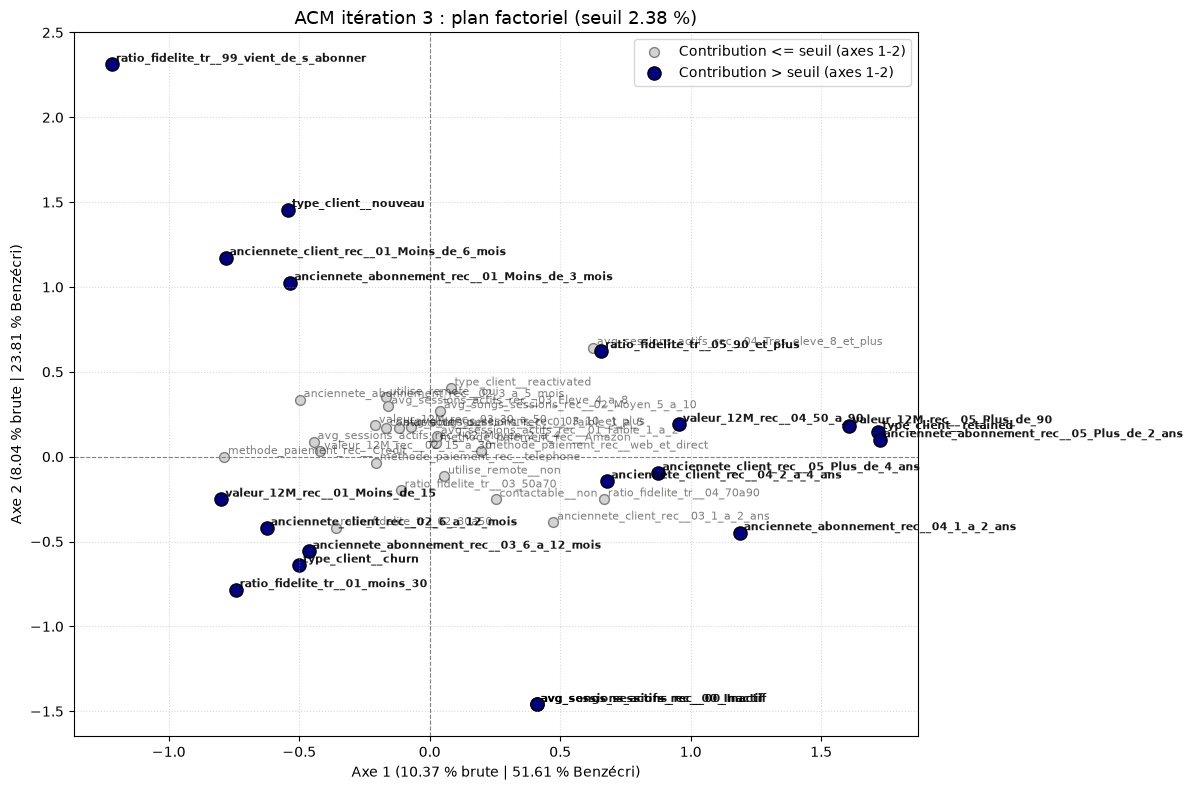

Critère de contribution aux cinq premiers axes respecté.


In [8]:
# Exécution du seul scénario retenu (ACM 3)
resultats_iteration_3 = executer_iteration_3(
    donnees_nettoyees,
    regroupements_finaux,
    graine=42,
    n_axes_tableau=5,
    n_axes_proximite=5,
    proportion_selection=PROPORTION_SELECTION,
)

if not resultats_iteration_3["indices_echantillon"].equals(
    resultats_iteration_2["indices_echantillon"]
):
    raise AssertionError("Les échantillons des itérations 2 et 3 ne correspondent pas.")

if len(resultats_iteration_3["variables_a_revoir"]) != 0:
    print("Attention : certaines variables doivent être réexaminées avant de finaliser l'ACM.")
else:
    print("Critère de contribution aux cinq premiers axes respecté.")

### Comparaison des ACM 2 et 3

La comparaison porte sur les effectifs, les modalités, l'inertie des cinq premiers axes et les variables à réexaminer. Une augmentation de l'inertie n'est pas, à elle seule, une justification de regroupement.

In [9]:
def resumer_acm(nom, resultats):
    return {
        "Scénario": nom,
        "Individus": len(resultats["echantillon_acm"]),
        "Variables actives": len(resultats["variables_acm"]),
        "Modalités actives": len(resultats["tableau_modalites"]),
        "Inertie brute axes 1-5 (%)": float(np.sum(resultats["brute"][:5])),
        "Inertie Benzécri axes 1-5 (%)": float(np.sum(resultats["benzecri"][:5])),
        "Variables à réexaminer": ", ".join(resultats["variables_a_revoir"]) or "aucune",
    }

bilan_final = pd.DataFrame([
    resumer_acm("ACM_2_reference", resultats_iteration_2),
    resumer_acm("ACM_3_final", resultats_iteration_3),
])
display(bilan_final)

chemin_experiences = RACINE / "resultats" / "experiences_acm"
chemin_experiences.mkdir(parents=True, exist_ok=True)
bilan_final.to_csv(chemin_experiences / "bilan_final_acm.csv", index=False)

,Scénario,Individus,Variables actives,Modalités actives,Inertie brute axes 1-5 (%),Inertie Benzécri axes 1-5 (%),Variables à réexaminer
0,ACM_2_reference,68218,10,43,34.475282,96.218444,aucune
1,ACM_3_final,68218,10,42,35.542344,96.324591,aucune


In [10]:
# Contributions maximales des variables aux cinq premiers axes
colonnes_contribution = [f"Contrib Axe {indice} (%)" for indice in range(1, 6)]

def contributions_par_variable(resultats):
    tableau = resultats["tableau_modalites"]
    return tableau.groupby("Variable")[colonnes_contribution].max().max(axis=1)

contributions_reference = contributions_par_variable(resultats_iteration_2)
contributions_finales = contributions_par_variable(resultats_iteration_3)
comparaison_contributions = pd.DataFrame({
    "Maximum ACM 2 (%)": contributions_reference,
    "Maximum ACM 3 (%)": contributions_finales,
})
comparaison_contributions["Seuil ACM 3 (%)"] = resultats_iteration_3["seuil_contribution"]
comparaison_contributions["Variable à réexaminer"] = (
    comparaison_contributions.index.isin(resultats_iteration_3["variables_a_revoir"])
)
display(comparaison_contributions)
comparaison_contributions.to_csv(chemin_experiences / "contributions_finales_acm.csv")

,Maximum ACM 2 (%),Maximum ACM 3 (%),Seuil ACM 3 (%),Variable à réexaminer
Variable,,,,
anciennete_abonnement_rec,10.789516,10.792985,2.380952,False
anciennete_client_rec,10.641636,10.624825,2.380952,False
avg_sessions_actifs_rec,23.463807,23.446210,2.380952,False
avg_songs_sessions_rec,23.463807,23.446210,2.380952,False
contactable,8.058004,8.020308,2.380952,False
methode_paiement_rec,4.339587,4.229327,2.380952,False
ratio_fidelite_tr,7.451295,7.441121,2.380952,False
type_client,16.967159,16.971004,2.380952,False
utilise_remote,2.562867,2.533292,2.380952,False


### Décision finale

Le seul regroupement retenu est celui des modalités **« 10–20 » et « 20 et plus » chansons par session**, réunies sous la modalité `03_10_et_plus`.

Les modalités de sessions actives, de fidélité et d'ancienneté restent séparées afin de préserver des distinctions métier pertinentes. Après vérification de la contribution des variables aux cinq premiers axes, l'ACM 3 constitue le modèle de référence pour la future CAH.

In [11]:
# Traçabilité de la décision métier
justification_regroupement = pd.DataFrame([{
    "Variable": "avg_songs_sessions_rec",
    "Modalité A": "03_Eleve_10_a_20",
    "Modalité B": "04_Tres_eleve_20_et_plus",
    "Modalité finale": "03_10_et_plus",
    "Décision": "retenu",
    "Justification métier": "Deux modalités correspondant à une consommation élevée de chansons par session.",
}])
display(justification_regroupement)
justification_regroupement.to_csv(
    chemin_experiences / "decisions_regroupement.csv", index=False
)

,Variable,Modalité A,Modalité B,Modalité finale,Décision,Justification métier
0,avg_songs_sessions_rec,03_Eleve_10_a_20,04_Tres_eleve_20_et_plus,03_10_et_plus,retenu,Deux modalités correspondant à une consommatio...


## Diagnostic des valeurs propres de l'ACM final

L'analyse ci-dessous utilise **l'itération 3**. Le nombre d'axes à retenir pour la classification est déterminé dans `03_cah.ipynb`.

In [12]:
# ============================================================
# DIAGNOSTIC DES VALEURS PROPRES DU MODÈLE FINAL
# ============================================================

valeurs_propres = resultats_iteration_3["modele"].eigenvalues_

print("Valeurs propres :")
for i, valeur in enumerate(valeurs_propres, start=1):
    print(f"Dim.{i} : {valeur:.4f}")

# Inertie brute cumulée
inertie_cumulee = valeurs_propres.cumsum() / valeurs_propres.sum()

print("\nInertie cumulée :")
for i, valeur in enumerate(inertie_cumulee, start=1):
    print(f"Dim.{i} : {valeur:.2%}")

Valeurs propres :
Dim.1 : 0.3317
Dim.2 : 0.2574
Dim.3 : 0.2102
Dim.4 : 0.1750
Dim.5 : 0.1631
Dim.6 : 0.1411
Dim.7 : 0.1313
Dim.8 : 0.1270
Dim.9 : 0.1128
Dim.10 : 0.1123
Dim.11 : 0.1101
Dim.12 : 0.1019
Dim.13 : 0.1005
Dim.14 : 0.1001
Dim.15 : 0.0993
Dim.16 : 0.0961
Dim.17 : 0.0933
Dim.18 : 0.0887
Dim.19 : 0.0865
Dim.20 : 0.0843
Dim.21 : 0.0801
Dim.22 : 0.0707
Dim.23 : 0.0677
Dim.24 : 0.0559
Dim.25 : 0.0519
Dim.26 : 0.0479
Dim.27 : 0.0383
Dim.28 : 0.0211
Dim.29 : 0.0192
Dim.30 : 0.0147
Dim.31 : 0.0098
Dim.32 : 0.0000

Inertie cumulée :
Dim.1 : 10.37%
Dim.2 : 18.41%
Dim.3 : 24.98%
Dim.4 : 30.45%
Dim.5 : 35.54%
Dim.6 : 39.95%
Dim.7 : 44.06%
Dim.8 : 48.02%
Dim.9 : 51.55%
Dim.10 : 55.06%
Dim.11 : 58.50%
Dim.12 : 61.69%
Dim.13 : 64.83%
Dim.14 : 67.95%
Dim.15 : 71.06%
Dim.16 : 74.06%
Dim.17 : 76.98%
Dim.18 : 79.75%
Dim.19 : 82.45%
Dim.20 : 85.08%
Dim.21 : 87.59%
Dim.22 : 89.80%
Dim.23 : 91.91%
Dim.24 : 93.66%
Dim.25 : 95.28%
Dim.26 : 96.78%
Dim.27 : 97.97%
Dim.28 : 98.63%
Dim.29 : 99.23%
Dim.3

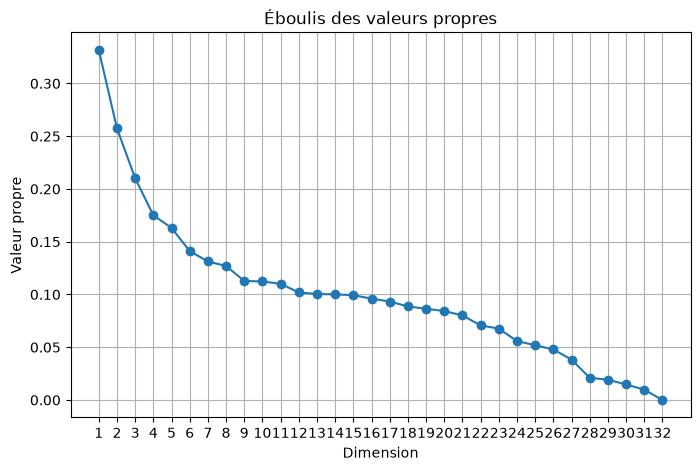

In [13]:
## Éboulis des valeurs propres

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(valeurs_propres) + 1),
    valeurs_propres,
    marker="o"
)

plt.xlabel("Dimension")
plt.ylabel("Valeur propre")
plt.title("Éboulis des valeurs propres")
plt.xticks(range(1, len(valeurs_propres) + 1))
plt.grid(True)

plt.show()

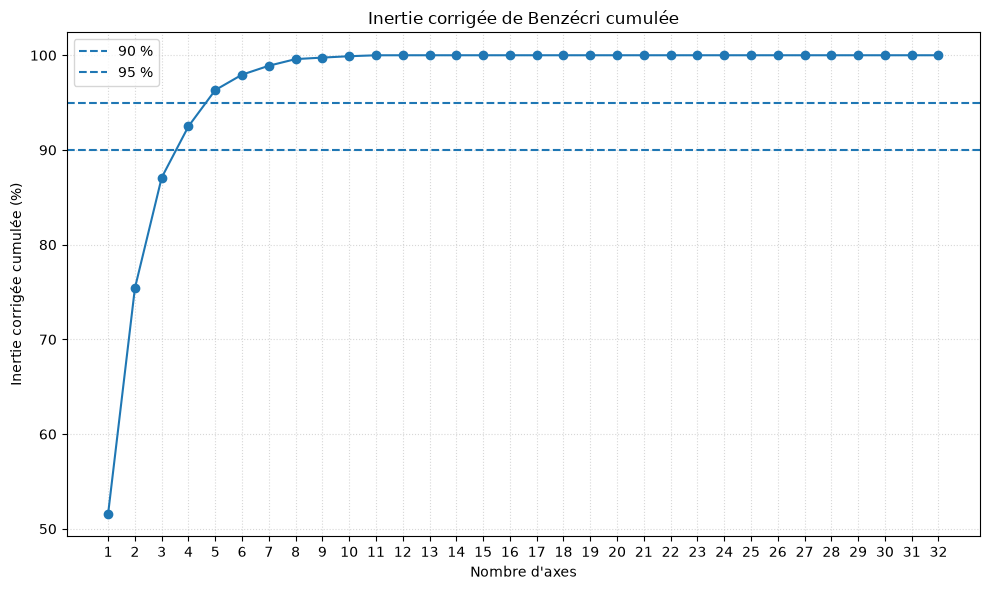

In [14]:
## Inertie corrigée de Benzécri cumulée

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(resultats_iteration_3["benzecri"]) + 1),
    np.cumsum(resultats_iteration_3["benzecri"]),
    marker='o'
)

plt.axhline(
    90,
    linestyle='--',
    label='90 %'
)

plt.axhline(
    95,
    linestyle='--',
    label='95 %'
)

plt.xlabel("Nombre d'axes")
plt.ylabel("Inertie corrigée cumulée (%)")
plt.title("Inertie corrigée de Benzécri cumulée")
plt.xticks(range(1, len(resultats_iteration_3["benzecri"]) + 1))
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

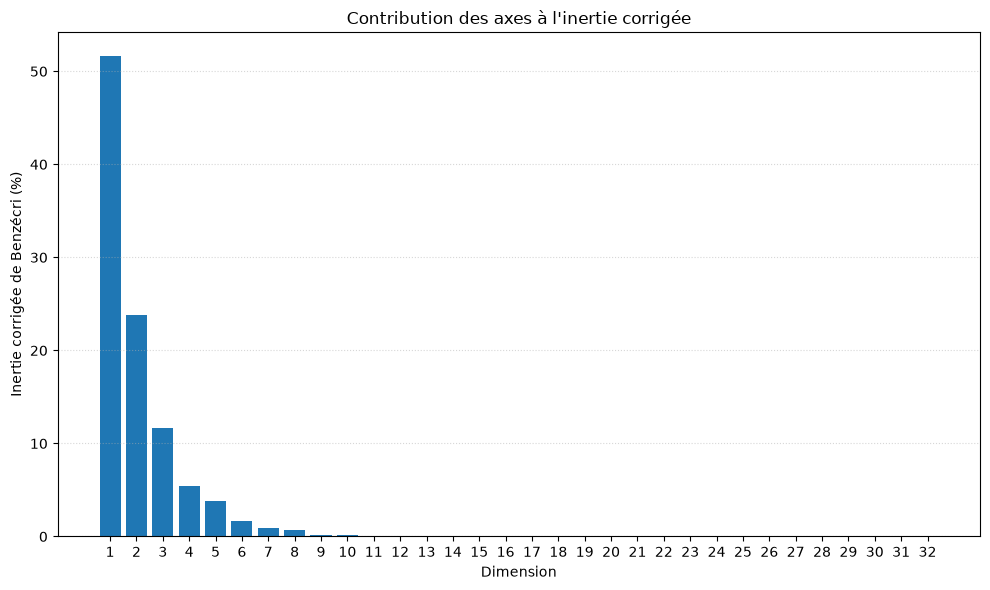

In [15]:
## Inertie corrigée de Benzécri par axe

plt.figure(figsize=(10, 6))

plt.bar(
    range(1, len(resultats_iteration_3["benzecri"]) + 1),
    resultats_iteration_3["benzecri"]
)

plt.xlabel("Dimension")
plt.ylabel("Inertie corrigée de Benzécri (%)")
plt.title("Contribution des axes à l'inertie corrigée")
plt.xticks(range(1, len(resultats_iteration_3["benzecri"]) + 1))
plt.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

## Export du modèle factoriel final pour la CAH

Les coordonnées **complètes** de l'ACM 3 sont exportées, sans choisir encore le nombre d'axes pour la CAH. Les identifiants et l'ordre des individus de l'échantillon sont conservés séparément, de même que le modèle ajusté et la liste des modalités actives.

La configuration `regroupements_acm_finaux` devra également être appliquée lors de la préparation des futurs clients.

In [16]:
# Export des coordonnées complètes, des identifiants et du modèle final
import json
import joblib

resultats_finaux = resultats_iteration_3
coordonnees_factorielles = resultats_finaux["modele"].row_coordinates(
    resultats_finaux["tableau_disjonctif"]
)

if not coordonnees_factorielles.index.equals(resultats_finaux["echantillon_acm"].index):
    raise AssertionError("L'ordre des coordonnées ne correspond pas à celui des individus.")

chemin_resultats = RACINE / "resultats"
chemin_modeles = RACINE / "modeles"
chemin_resultats.mkdir(parents=True, exist_ok=True)
chemin_modeles.mkdir(parents=True, exist_ok=True)

coordonnees_factorielles.to_csv(
    chemin_resultats / "coordonnees_factorielles.csv", index=False
)

# Récupération des identifiants depuis les données brutes, avant nettoyage.
# Les index d'origine doivent être conservés pendant la préparation et l'échantillonnage.
indices_echantillon = resultats_finaux["echantillon_acm"].index

if not donnees_brutes.index.is_unique:
    raise ValueError("L'index des données brutes doit être unique pour retrouver les individus.")
if not indices_echantillon.is_unique:
    raise ValueError("L'index de l'échantillon contient des doublons.")
if not indices_echantillon.isin(donnees_brutes.index).all():
    raise ValueError(
        "Certains indices de l'échantillon sont absents des données brutes. "
        "Vérifier la conservation de l'index dans preparer_donnees()."
    )

if "id_anonyme" in donnees_brutes.columns:
    identifiants = donnees_brutes.loc[indices_echantillon, ["id_anonyme"]].copy()
    colonne_identifiant = "id_anonyme"
    if identifiants["id_anonyme"].isna().any():
        raise ValueError("Certains identifiants anonymes sont manquants.")
    if identifiants["id_anonyme"].duplicated().any():
        raise ValueError("Les identifiants anonymes ne sont pas uniques.")
else:
    # Repli explicite : index technique, et non identifiant métier du client.
    identifiants = pd.DataFrame(
        {"indice_ligne_source": indices_echantillon.to_numpy()},
        index=indices_echantillon,
    )
    colonne_identifiant = "indice_ligne_source"
    print(
        "Attention : id_anonyme est absent des données brutes. "
        "La correspondance repose sur l'index des lignes sources."
    )

if not identifiants.index.equals(coordonnees_factorielles.index):
    raise AssertionError("L'ordre des identifiants et des coordonnées diffère.")

identifiants = identifiants.reset_index(drop=True)
identifiants.insert(0, "position_echantillon", np.arange(len(identifiants)))
identifiants.to_csv(
    chemin_resultats / "correspondance_clients_acm.csv", index=False
)

joblib.dump(resultats_finaux["modele"], chemin_modeles / "acm_final.joblib")
metadonnees = {
    "iteration": 3,
    "graine": 42,
    "fraction_echantillon": 0.20,
    "variables_actives": resultats_finaux["variables_acm"],
    "modalites_actives": list(resultats_finaux["tableau_disjonctif"].columns),
    "nombre_axes_calcules": int(coordonnees_factorielles.shape[1]),
    "regroupements_acm_finaux": regroupements_finaux,
    "fichiers_coordonnees": "resultats/coordonnees_factorielles.csv",
    "fichier_correspondance": "resultats/correspondance_clients_acm.csv",
    "colonne_identifiant": colonne_identifiant,
}
with (chemin_modeles / "acm_final_metadonnees.json").open("w", encoding="utf-8") as fichier:
    json.dump(metadonnees, fichier, indent=2, ensure_ascii=False)

print(f"Coordonnées finales : {coordonnees_factorielles.shape}")
print(f"Individus référencés : {len(identifiants)}")
print("Modèle factoriel final et métadonnées enregistrés.")

Coordonnées finales : (68218, 32)
Individus référencés : 68218
Modèle factoriel final et métadonnées enregistrés.
